<a href="https://colab.research.google.com/github/manikanta-eng/python-project/blob/main/heart_diesease_prdiction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully")

All libraries imported successfully


In [ ]:
heart = fetch_ucirepo(id=45)

X = heart.data.features.copy()
y = heart.data.targets.iloc[:, 0].copy()

df = X.copy()
df["num"] = y

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Loaded Successfully
Dataset Shape: (303, 14)

First 5 Records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB
None

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal   

In [ ]:
df = df.replace("?", np.nan)

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["num"])

X = df.drop("num", axis=1)

y = (df["num"] > 0).astype(int)

print("Data Cleaning Completed")

print("\nMissing Values After Conversion:")
print(X.isnull().sum())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Labels:")
print("0 = No Heart Disease")
print("1 = Heart Disease Present")

Data Cleaning Completed

Missing Values After Conversion:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Target Distribution:
num
0    164
1    139
Name: count, dtype: int64

Target Labels:
0 = No Heart Disease
1 = Heart Disease Present


In [ ]:
print("Dataset Shape:", df.shape)

print("\nStatistical Description:")
display(df.describe())

print("\nTarget Count:")
print(y.value_counts())

Dataset Shape: (303, 14)

Statistical Description:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Target Count:
num
0    164
1    139
Name: count, dtype: int64


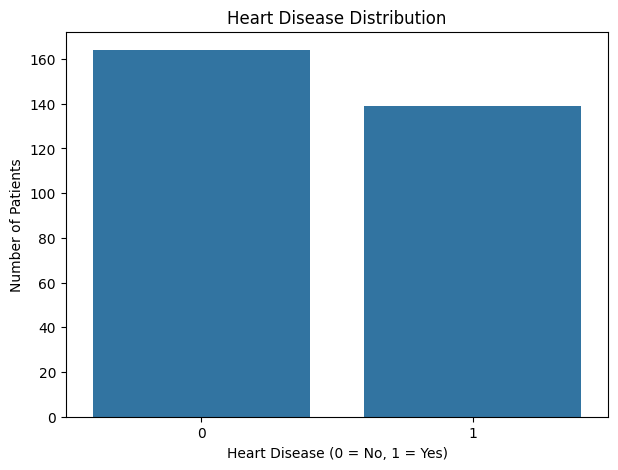

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(x=y)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

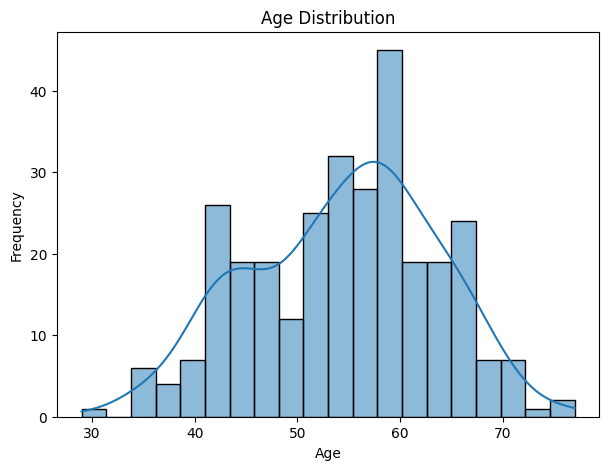

In [ ]:
plt.figure(figsize=(7,5))

sns.histplot(df["age"], bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

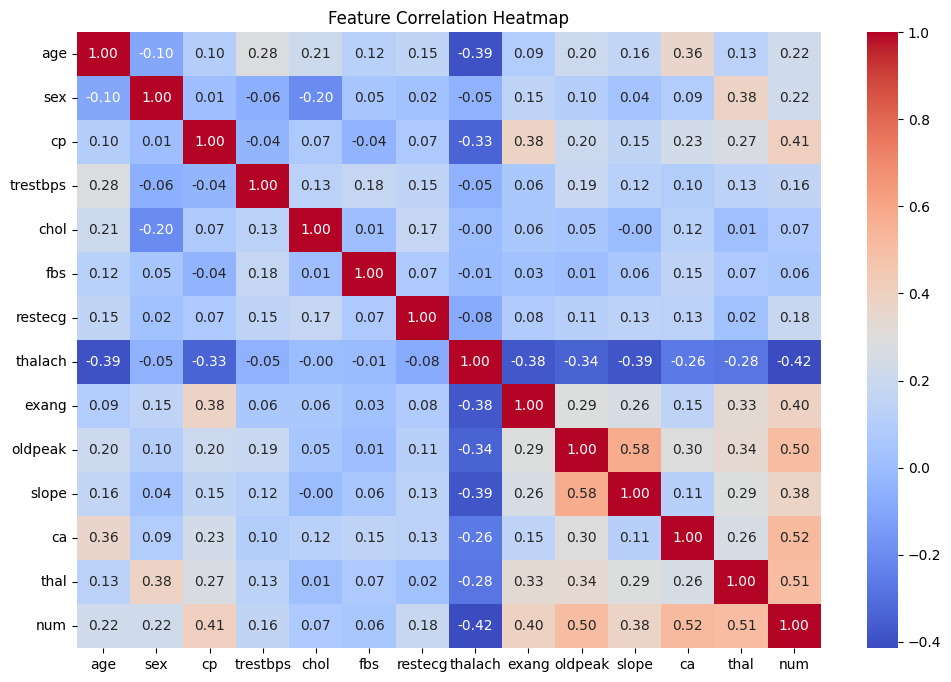

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

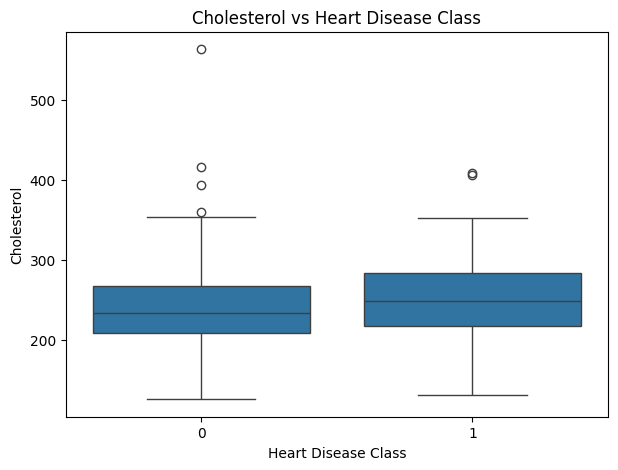

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(
    x=y,
    y=df["chol"]
)

plt.title("Cholesterol vs Heart Disease Class")
plt.xlabel("Heart Disease Class")
plt.ylabel("Cholesterol")

plt.show()

In [ ]:
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numerical_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and Testing Split Completed")

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training and Testing Split Completed
Training Data: (242, 13)
Testing Data: (61, 13)


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf")
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-Score:", round(f1, 3))

print("\nAll Models Trained Successfully")


Model: Logistic Regression
Accuracy: 88.52 %
Precision: 0.839
Recall: 0.929
F1-Score: 0.881

Model: Decision Tree
Accuracy: 73.77 %
Precision: 0.676
Recall: 0.821
F1-Score: 0.742

Model: Random Forest
Accuracy: 85.25 %
Precision: 0.806
Recall: 0.893
F1-Score: 0.847

Model: KNN
Accuracy: 88.52 %
Precision: 0.862
Recall: 0.893
F1-Score: 0.877

Model: SVM
Accuracy: 88.52 %
Precision: 0.839
Recall: 0.929
F1-Score: 0.881

All Models Trained Successfully


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print("MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,88.52%,83.87%,92.86%,88.14%
4,SVM,88.52%,83.87%,92.86%,88.14%
3,KNN,88.52%,86.21%,89.29%,87.72%
2,Random Forest,85.25%,80.65%,89.29%,84.75%
1,Decision Tree,73.77%,67.65%,82.14%,74.19%


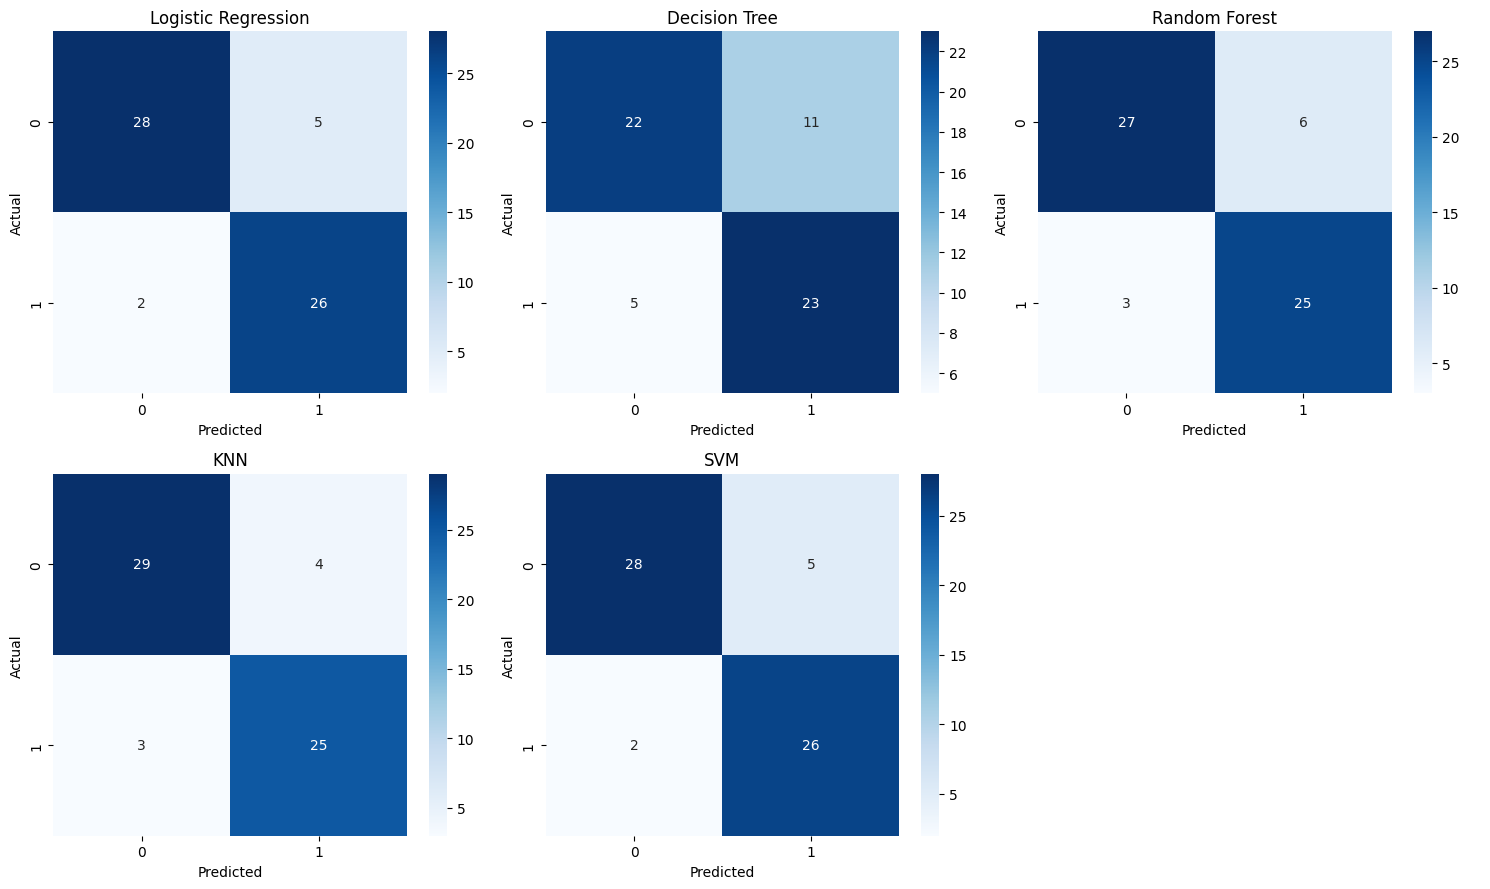

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, (name, model) in enumerate(
    trained_models.items()
):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

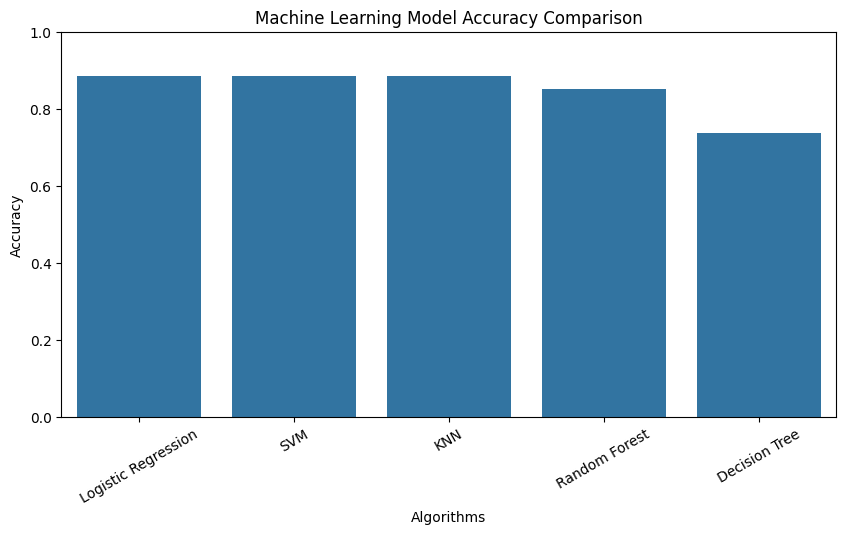

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)

plt.ylim(0, 1)

plt.show()

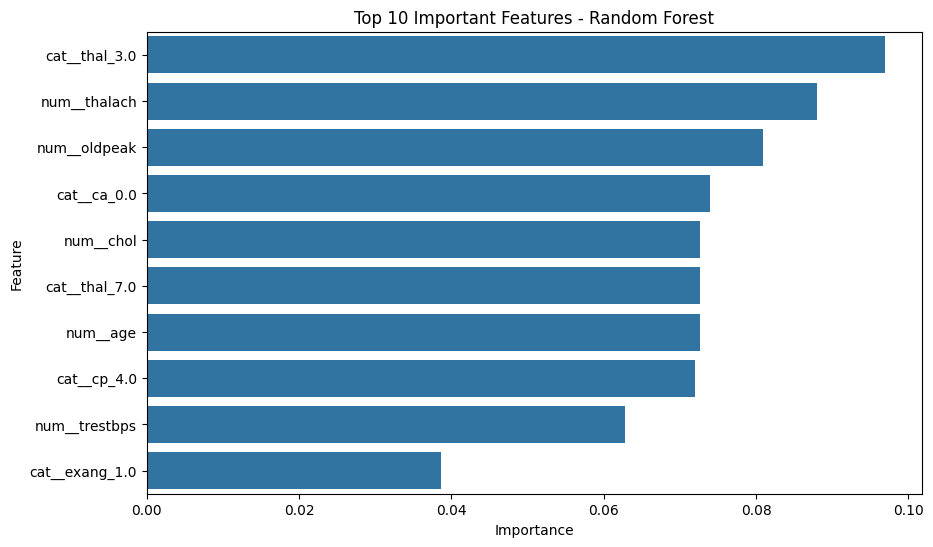

,Feature,Importance
25,cat__thal_3.0,0.096908
3,num__thalach,0.088056
4,num__oldpeak,0.080950
21,cat__ca_0.0,0.073941
2,num__chol,0.072691
27,cat__thal_7.0,0.072684
0,num__age,0.072585
10,cat__cp_4.0,0.072017
1,num__trestbps,0.062835
17,cat__exang_1.0,0.038621


In [ ]:
rf_pipeline = trained_models["Random Forest"]

feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    rf_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")

plt.show()

display(importance_df)

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

final_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=[
            "No Heart Disease",
            "Heart Disease Present"
        ],
        zero_division=0
    )
)

print("\nFinal Model Evaluation Completed")

Best Model: Logistic Regression

Classification Report:
                       precision    recall  f1-score   support

     No Heart Disease       0.93      0.85      0.89        33
Heart Disease Present       0.84      0.93      0.88        28

             accuracy                           0.89        61
            macro avg       0.89      0.89      0.89        61
         weighted avg       0.89      0.89      0.89        61


Final Model Evaluation Completed
